In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
import numpy as np
import scanpy as sc
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import re


In [2]:
adata_RRmap = sc.read_h5ad('../data/RREAE_5k_raw.h5ad')
adata_EAE5K = sc.read_h5ad('../data/eae_5k_raw.h5ad')
adata_mtDSB = sc.read_h5ad('../data/mtDNA_DSB_5k_raw.h5ad')

In [3]:
adata_EAE5K.obs["sample_extracted"] = adata_EAE5K.obs["run"].str.extract(r"__(G\d+_L\d+)__")
adata_RRmap.obs["sample_extracted"] = adata_RRmap.obs["sample"].str.extract(r"__(S\d+-[A-Za-z]+\d+)__")
adata_mtDSB.obs["sample_extracted"] = adata_mtDSB.obs["run"].str.extract(r"__(RB\d+)__")

In [4]:
adata_mtDSB.obs_names_make_unique()
adata_RRmap.obs_names_make_unique()
adata_EAE5K.obs_names_make_unique()

In [5]:
adata_mtDSB.obs['project'] = 'mtDSB'
adata_RRmap.obs['project'] = 'RREAE'
adata_EAE5K.obs['project'] = 'Chronic EAE'
ad = sc.concat(
    {
        "RRmap": adata_RRmap,
        "EAE5K": adata_EAE5K,
        "mtDSB": adata_mtDSB,
    },
    label="dataset",       # new column in .obs
    keys=None,             # use dict keys above
    index_unique="-",      # make indices unique: barcode-dataset
    join="outer",          # keep all genes (union)
    merge="same"           # only merge .obs/.var columns that are identical
)

In [6]:
ad.write('../data/integrated_2.h5ad')

In [7]:
# 2) (Optional) light filtering
sc.pp.filter_cells(ad, min_counts=40)      # tune if needed
sc.pp.filter_genes(ad, min_cells=5)

# 3) Normalize & log1p (sparse-friendly in modern Scanpy)
sc.pp.normalize_total(ad, target_sum=1e4)
sc.pp.log1p(ad)

# 4) No scaling (keeps sparsity). Compute PCs via TruncatedSVD (no centering; OK for huge sparse)
n_comps = 50
svd = TruncatedSVD(n_components=n_comps, random_state=0)
X_pca = svd.fit_transform(ad.X)  # returns dense (cells × PCs), but only 50 dims
ad.obsm["X_pca"] = X_pca.astype(np.float32)
ad.uns["pca"] = {
    "variance_ratio": svd.explained_variance_ratio_.astype(np.float32),
    "variance": (svd.explained_variance_ratio_ * svd.explained_variance_ratio_.sum()).astype(np.float32)  # placeholder
}

# 5) Subsample for graph building
rng = np.random.default_rng(0)
sub_n = min(200_000, ad.n_obs)  # adjust if you have more/less RAM
sub_idx = rng.choice(ad.n_obs, size=sub_n, replace=False)
sub_idx.sort()
mask_sub = np.zeros(ad.n_obs, dtype=bool)
mask_sub[sub_idx] = True

# 6) Neighbors + Leiden on the subsample only (fast & RAM-light)
ad_sub = ad[mask_sub].copy()
ad_sub.obsm["X_pca"] = ad.obsm["X_pca"][mask_sub]
sc.pp.neighbors(ad_sub, use_rep="X_pca", n_neighbors=30, method="umap")

In [8]:
sc.tl.leiden(ad_sub, resolution=2.5, key_added="leiden_sub")

# 7) Map all cells to the subsample: label transfer via kNN in PCA space
#    Fit index on subsample PCs and query all cells (streamable, RAM-friendly)
nbrs = NearestNeighbors(n_neighbors=5, algorithm="auto", n_jobs=-1)
nbrs.fit(ad_sub.obsm["X_pca"])

# For very tight memory, query in chunks
batch = 200_000
labels_sub = ad_sub.obs["leiden_sub"].to_numpy()
all_labels = np.empty(ad.n_obs, dtype=labels_sub.dtype)

for start in range(0, ad.n_obs, batch):
    stop = min(start + batch, ad.n_obs)
    dists, inds = nbrs.kneighbors(ad.obsm["X_pca"][start:stop])
    # majority vote from nearest subsample neighbors
    voted = np.array([
        np.argmax(np.bincount(labels_sub[inds[i]].astype(int)))
        for i in range(inds.shape[0])
    ], dtype=labels_sub.dtype)
    all_labels[start:stop] = voted

ad.obs["leiden"] = all_labels  # cluster for ALL 1.7M cells

# 8) (Optional) UMAP on subsample only, then embed the rest by kNN-averaging
sc.tl.umap(ad_sub, min_dist=0.3, spread=1.0)
ad_sub.obsm["X_umap"] = ad_sub.obsm["X_umap"].astype(np.float32)

# project full set to UMAP by averaging neighbors' coordinates
umap_full = np.empty((ad.n_obs, 2), dtype=np.float32)
for start in range(0, ad.n_obs, batch):
    stop = min(start + batch, ad.n_obs)
    _, inds = nbrs.kneighbors(ad.obsm["X_pca"][start:stop])
    umap_full[start:stop] = ad_sub.obsm["X_umap"][inds].mean(axis=1)
ad.obsm["X_umap"] = umap_full

IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out


In [9]:
import leidenalg

In [10]:
ad.obs.leiden = ad.obs.leiden.astype(str)

In [11]:
ad.write('../data/integrated_clustered.h5ad')

In [12]:
spatial = np.array(ad.obs[['x_centroid','y_centroid']])
ad.obsm['spatial'] = spatial

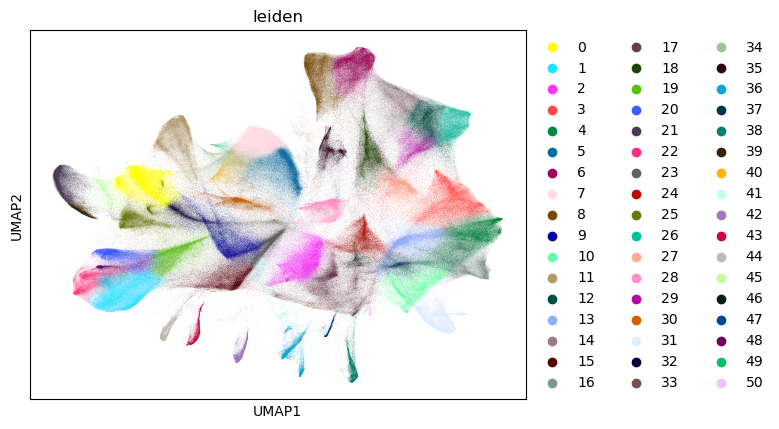

In [13]:
sc.pl.umap(ad, color = 'leiden')

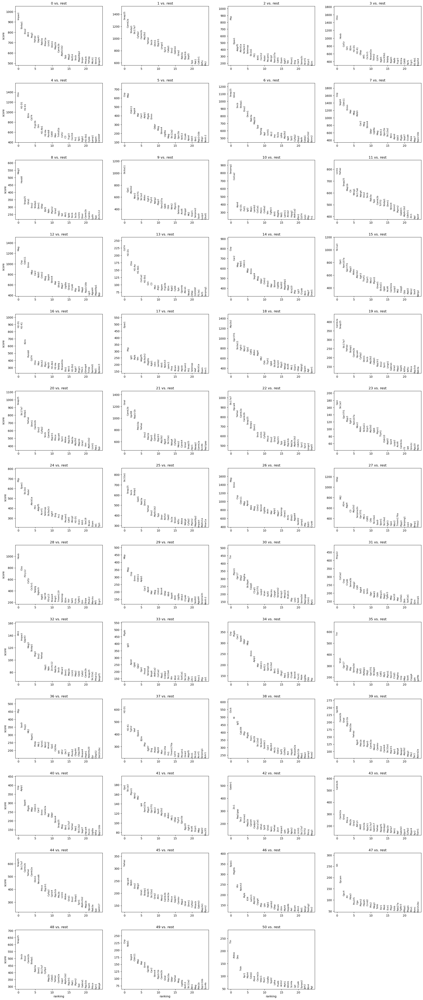

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,Impact,921.024963,3.860432,0.0,0.0
1,0,Stxbp1,831.868042,3.141176,0.0,0.0
2,0,Eno2,786.146179,3.162889,0.0,0.0
3,0,Ahi1,759.133789,4.718800,0.0,0.0
4,0,Peg3,749.554077,4.190259,0.0,0.0


In [14]:
# --- Find marker genes per cluster ---
sc.tl.rank_genes_groups(ad, groupby="leiden", method="t-test")
sc.pl.rank_genes_groups(ad, n_genes=25, sharey=False)

# get a tidy table of top markers
markers = sc.get.rank_genes_groups_df(ad, group=None)
markers.head()

In [15]:
marker_genes = pd.DataFrame({
    group: ad.uns['rank_genes_groups']['names'][group][:20]
    for group in ad.uns['rank_genes_groups']['names'].dtype.names
})


In [16]:
for col in marker_genes.columns: 
    print(col)
    genes = marker_genes[col].tolist()
    print(" ".join(genes))
    print(' ')

0
Impact Stxbp1 Eno2 Ahi1 Peg3 Ywhaz Gap43 Rab3a Prkar1a Uchl1 Dnm1 Map1b Camk2b Atp6v1b2 Syp Meg3 Rnf14 Sncb Mapk8ip2 Snrpn
 
1
Snap25 Camk2a Stxbp1 Slc17a7 Cyfip2 Camk2b Atp2b2 Ywhaz Sncb Dnm1 Ppp3r1 Lingo1 Syn1 Cabp1 Eno2 Gabra1 Gria2 Rab3a Ppp3cb Sept5
 
2
Pltp Epas1 Adgrf5 Abcb1a Slc9a3r2 Selenop Slc2a1 Flt1 Itih5 Cxcl12 Podxl Pecam1 Abcg2 Fam107a Cdh5 Esam Egfl7 Tek Prom1 Eng
 
3
Ctss Hexb Csf1r Grn B2m H2-D1 H2-K1 Gfap Aif1 Cx3cr1 Rnaset2a Trem2 Cd74 Itgb5 Unc93b1 Selplg Itgam Mafb Fcgr3 Il10ra
 
4
Ctss H2-D1 H2-K1 B2m Cd74 Fcgr2b Grn H2-Ab1 H2-Aa Psmb8 Cd68 Msn Tnfrsf1b Csf1r C3 Fcgr3 Cxcl16 Fn1 Spi1 Itgb2
 
5
Cnp Mbp Cldn11 Sept4 Mal Car2 Aplp1 Ptgds Ermn Qdpr Mog Stmn4 Ugt8a Mag Slc12a2 Aspa Gprc5b Rnf13 Cryab Apod
 
6
Snap25 Glra1 Sncb Stxbp1 Eno2 Dnm1 Rab3a Map1b Syp Ywhag Nsf Uchl1 Klc2 Ina Sv2a Ldhb Atp2b2 Nefl Syt2 Cyfip2
 
7
Cnp Sept4 Cldn11 Ermn Mal Mbp Aplp1 Car2 Mog Stmn4 Qdpr Ugt8a Mag Rnf13 Gprc5b Slc12a2 Bin1 Apod Edil3 Ptgds
 
8
Meg3 Hoxb8 Snap25 Glra1 Eno2 Stxbp

In [17]:
ad.obs

,x_centroid,y_centroid,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,...,nucleus_count,segmentation_method,run,sample,grid_label,sample_extracted,project,dataset,n_counts,leiden
cell_id,,,,,,,,,,,,,,,,,,,,,
aaadgfgj-1-RRmap,181.586823,1630.103394,474,0,0,0,3,0,477,48.317189,...,0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,20250605__132701__GoncaloTing_5kMouse_run2,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,474.0,8
aaaeckib-1-RRmap,212.154877,1685.950928,882,0,0,0,1,0,883,46.194845,...,1,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,20250605__132701__GoncaloTing_5kMouse_run2,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,882.0,8
aaaemkgl-1-RRmap,235.259537,1613.899048,1561,0,0,1,6,1,1569,112.800317,...,1,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,20250605__132701__GoncaloTing_5kMouse_run2,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,1561.0,6
aaagfkdi-1-RRmap,213.706497,1525.154907,1403,0,1,0,3,1,1408,71.708128,...,1,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,20250605__132701__GoncaloTing_5kMouse_run2,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,1403.0,8
aaagghkg-1-RRmap,196.850647,1526.920288,785,0,0,0,1,0,786,33.235001,...,0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,20250605__132701__GoncaloTing_5kMouse_run2,output-XETG00045__0054415__S1-B1__20250605__13...,GoncaloTing_5kMouse_run2,S1-B1,RREAE,RRmap,785.0,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
oifndkbo-1-mtDSB,2379.717529,4785.681152,419,0,0,0,0,0,419,42.221095,...,1,Segmented by nucleus expansion of 5.0µm,output-XETG00045__0060541__RB4676__20250917__1...,NaN,NaN,RB4676,mtDSB,mtDSB,419.0,9
oifolalk-1-mtDSB,2281.881104,4803.725098,219,0,0,0,0,0,219,36.170158,...,1,Segmented by nucleus expansion of 5.0µm,output-XETG00045__0060541__RB4676__20250917__1...,NaN,NaN,RB4676,mtDSB,mtDSB,219.0,32
oifphdni-1-mtDSB,2343.403564,4830.252441,76,0,0,0,0,0,76,14.946719,...,1,Segmented by nucleus expansion of 5.0µm,output-XETG00045__0060541__RB4676__20250917__1...,NaN,NaN,RB4676,mtDSB,mtDSB,76.0,23


RB4282


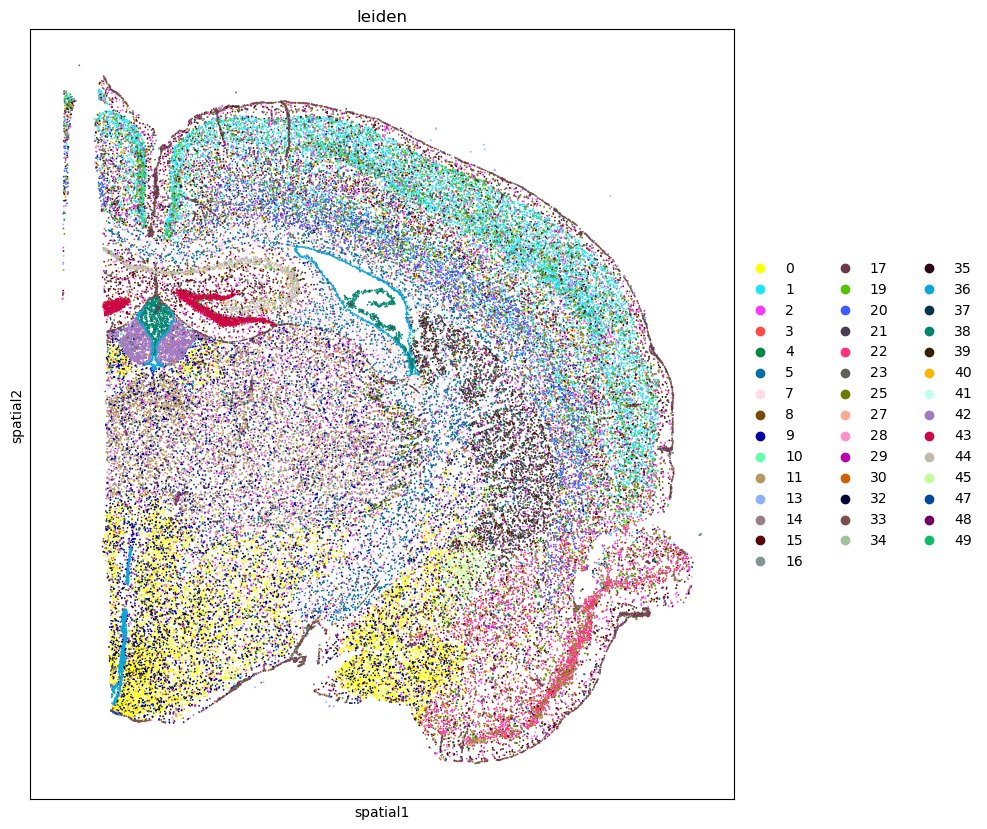

RB4350


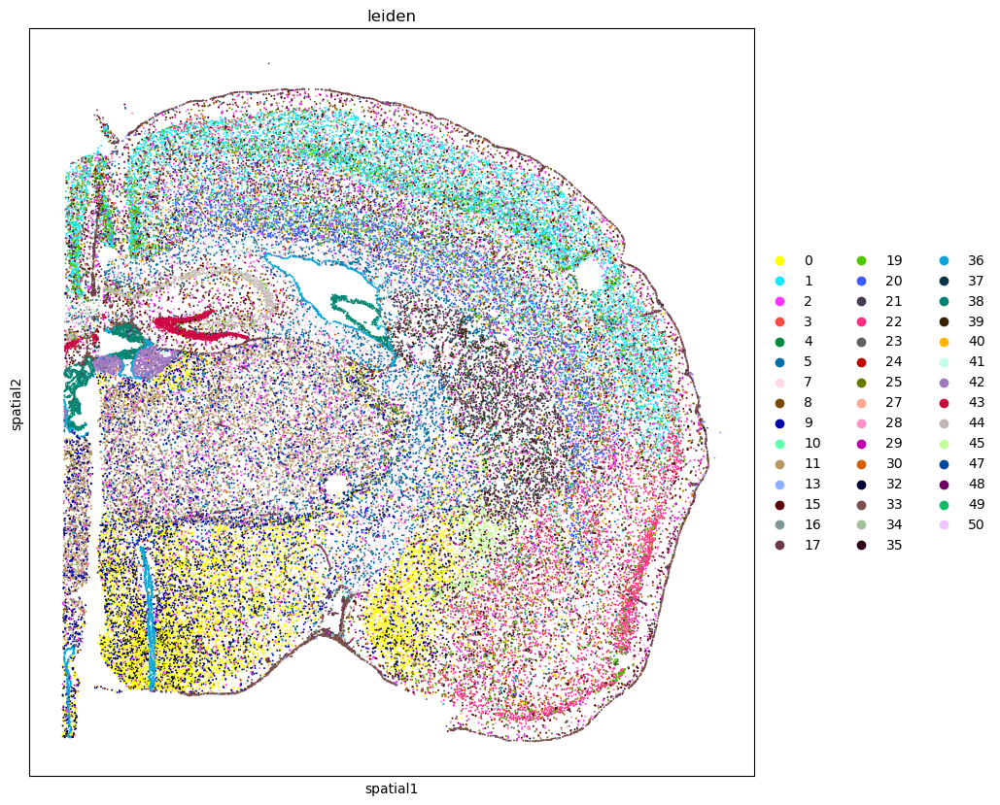

RB4401


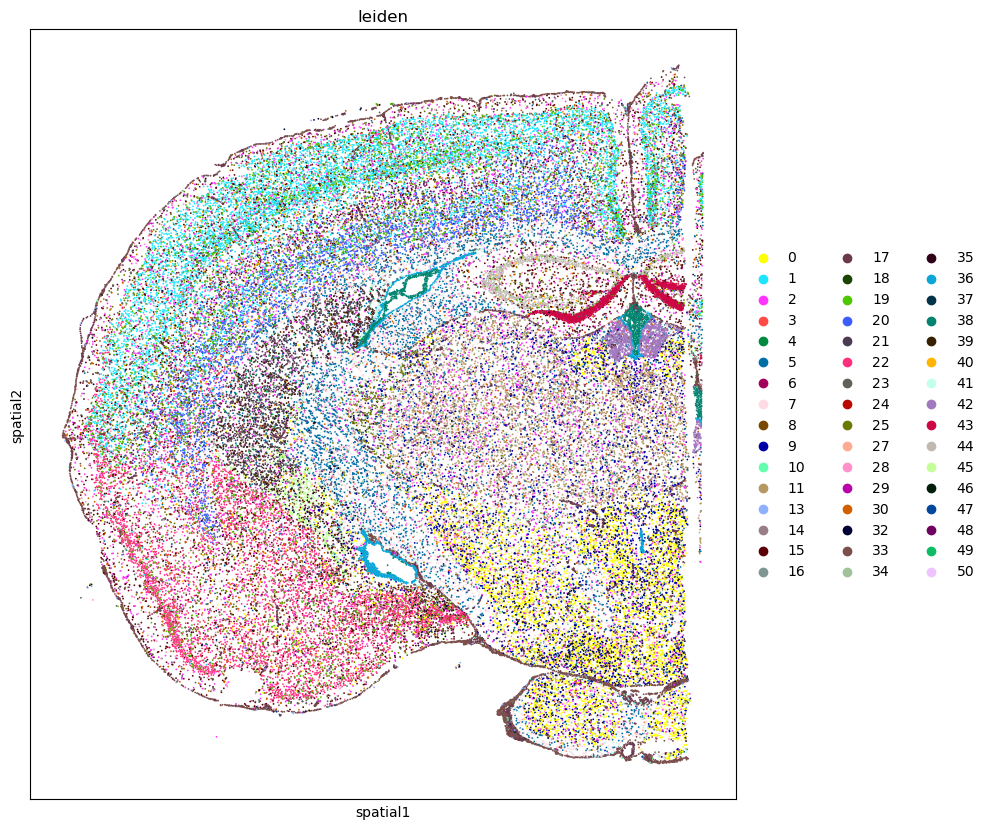

RB4403


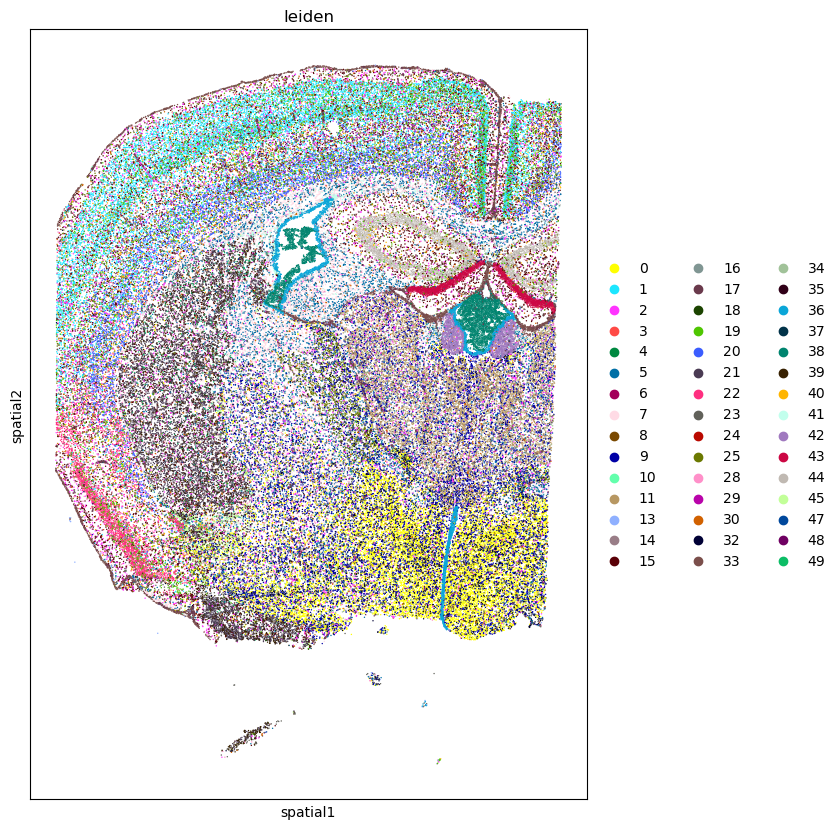

RB4405


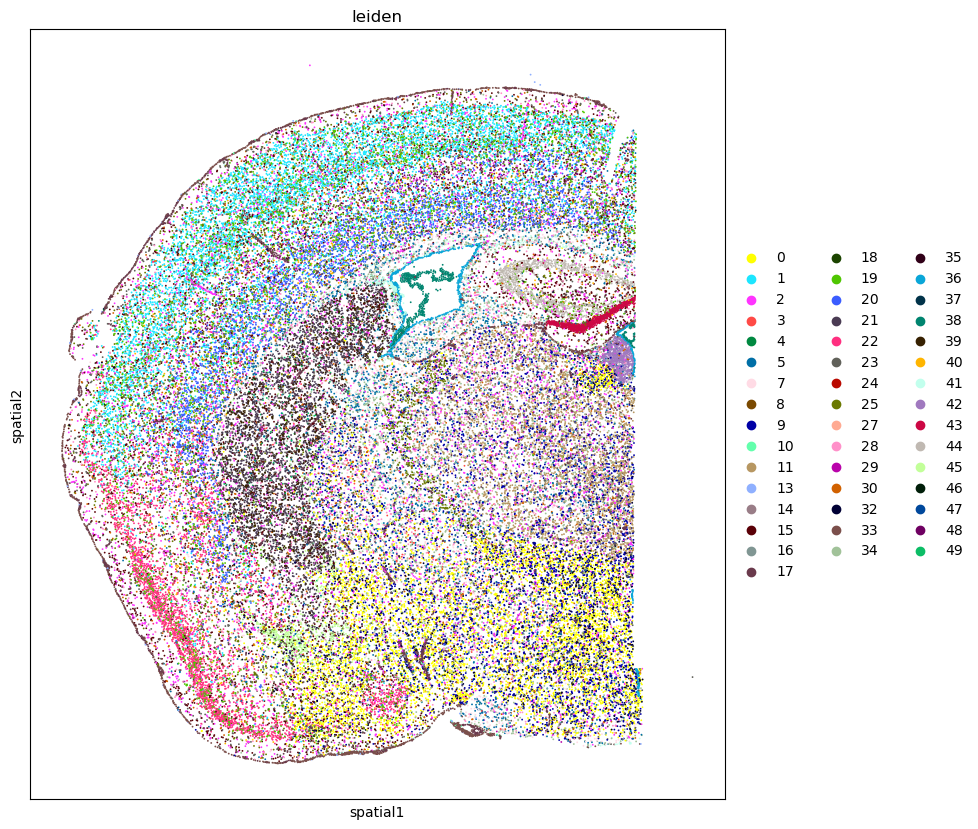

RB4498


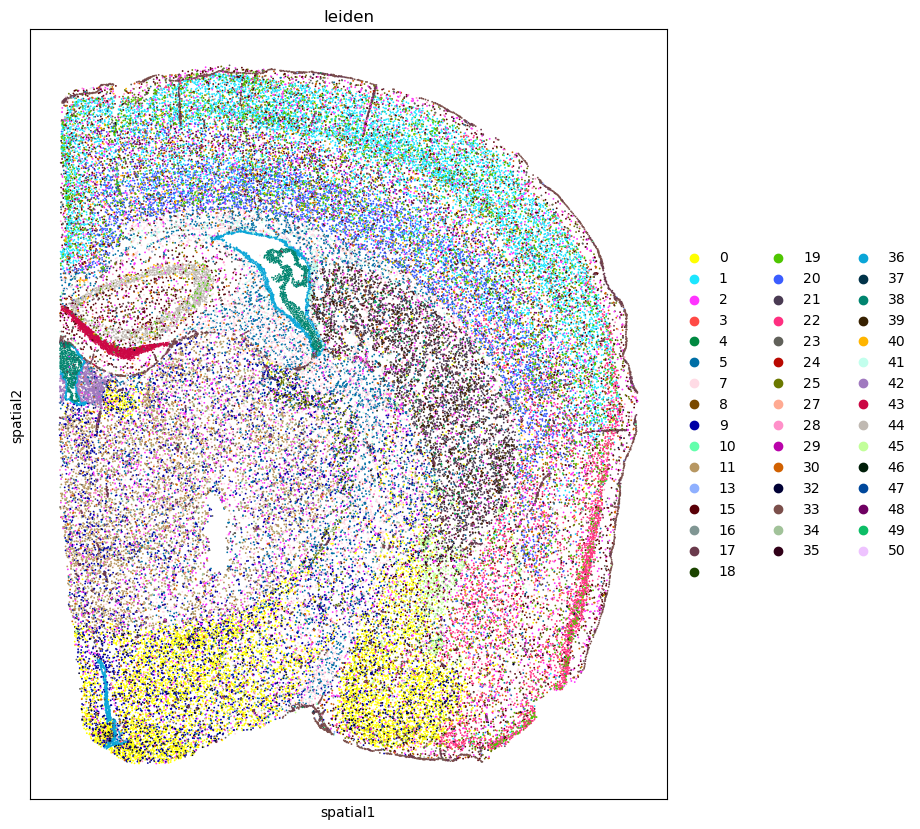

RB4620


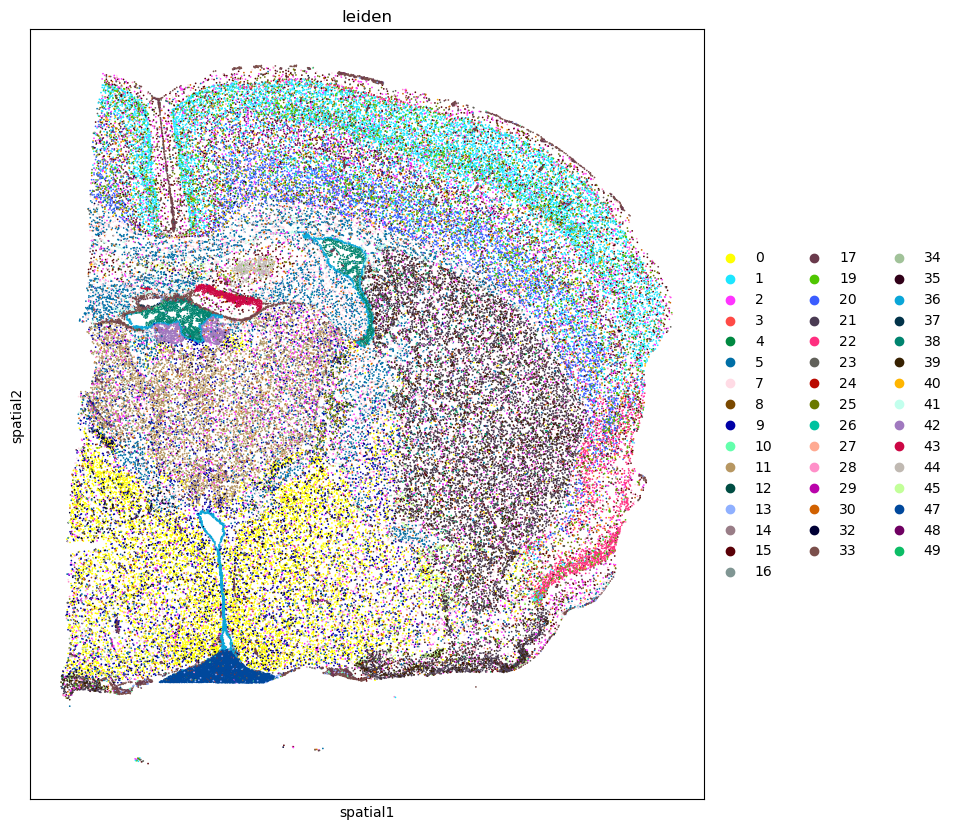

RB4627


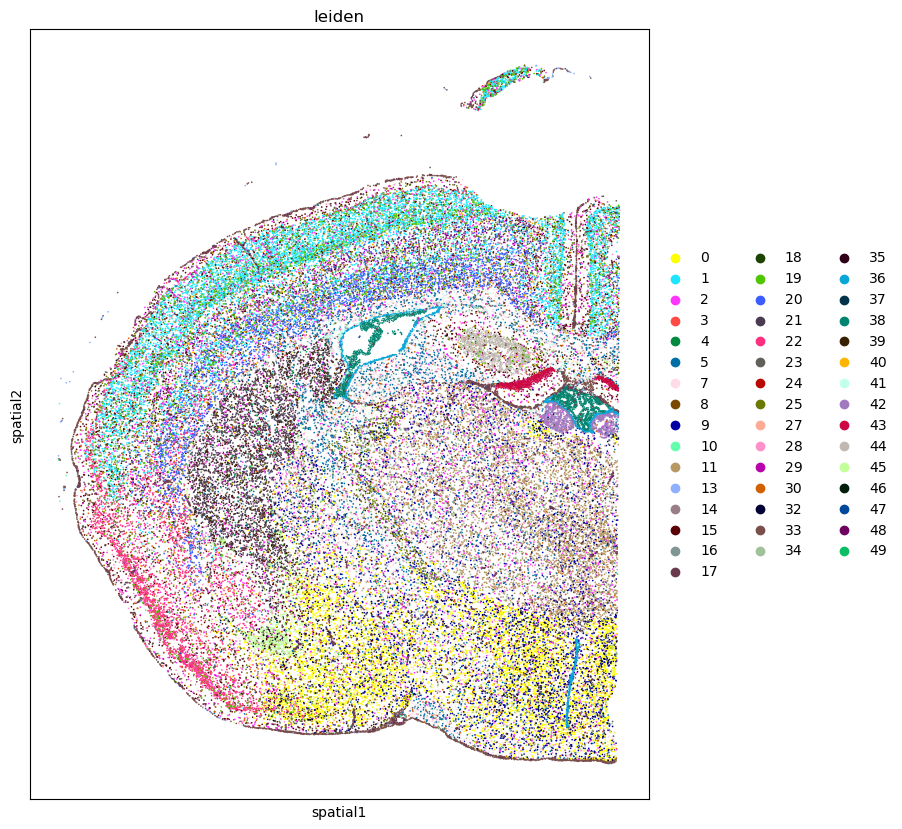

RB4630


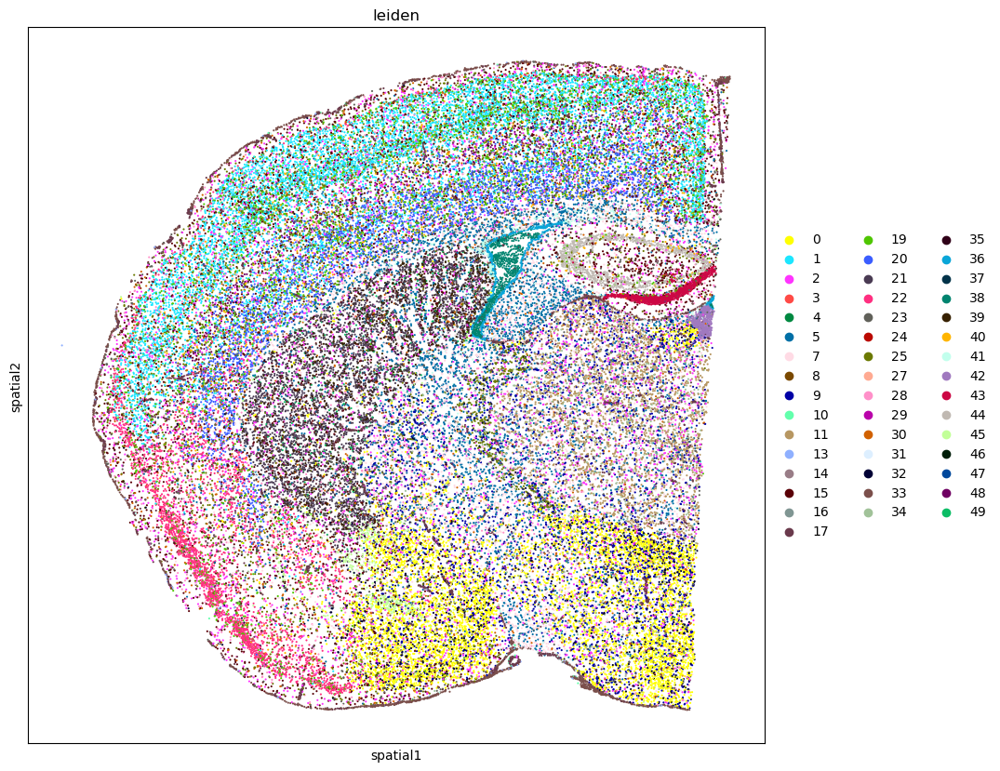

RB4653


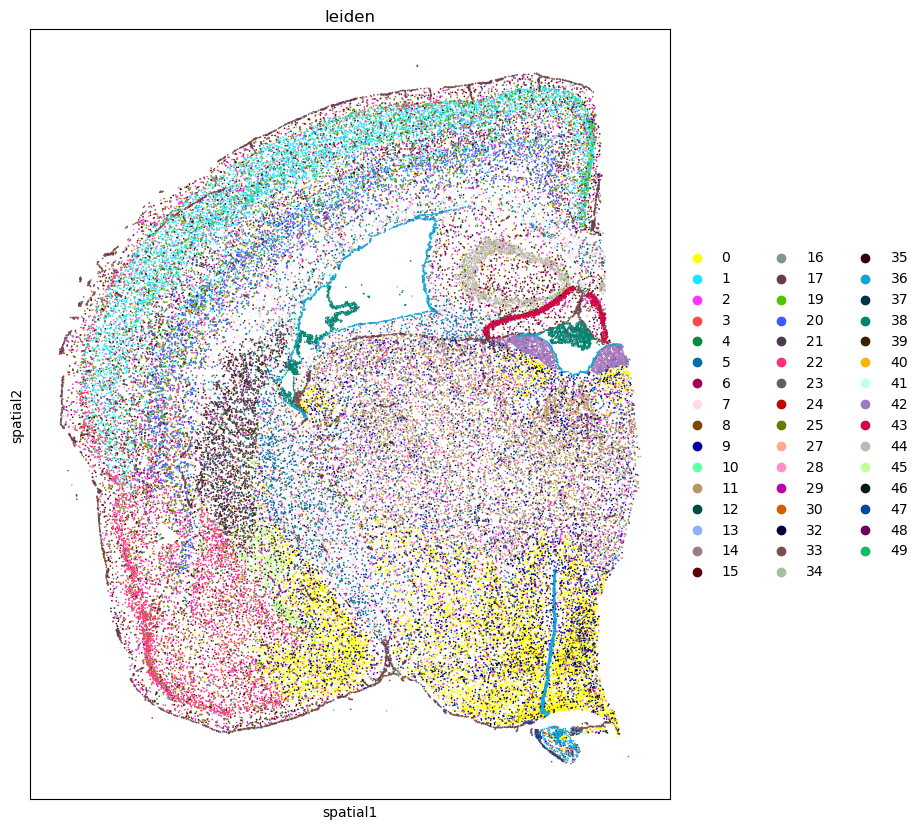

RB4658


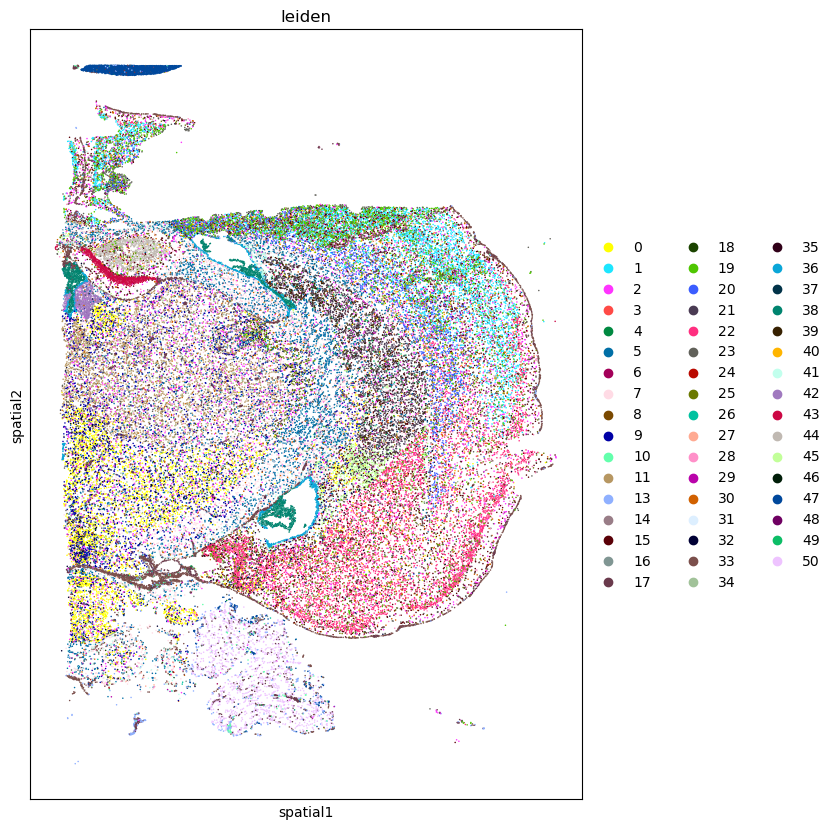

RB4676


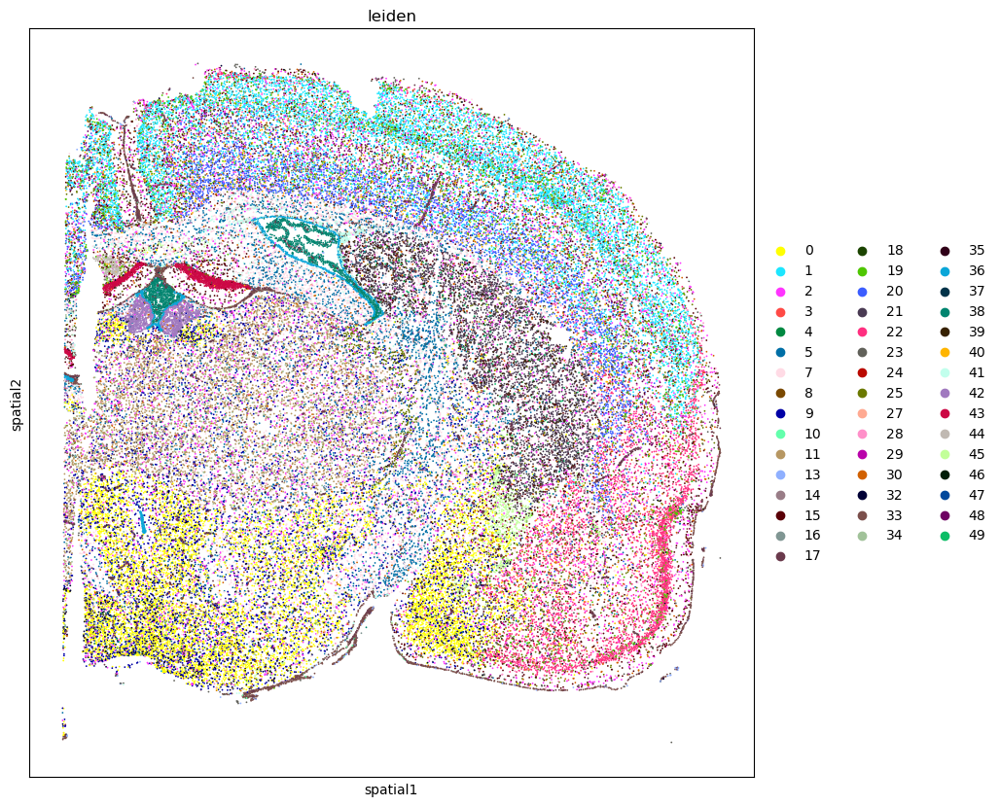

In [18]:
ad_mtDSB = ad[ad.obs.project == 'mtDSB']
for run in ad_mtDSB.obs['sample_extracted'].unique():
    print(run)
    ad_int = ad_mtDSB[ad_mtDSB.obs['sample_extracted'] == run]
    with plt.rc_context({'figure.figsize': (20, 10)}):
        sc.pl.spatial(ad_int, spot_size=15, color = 'leiden')
    plt.show()
    

S1-B1


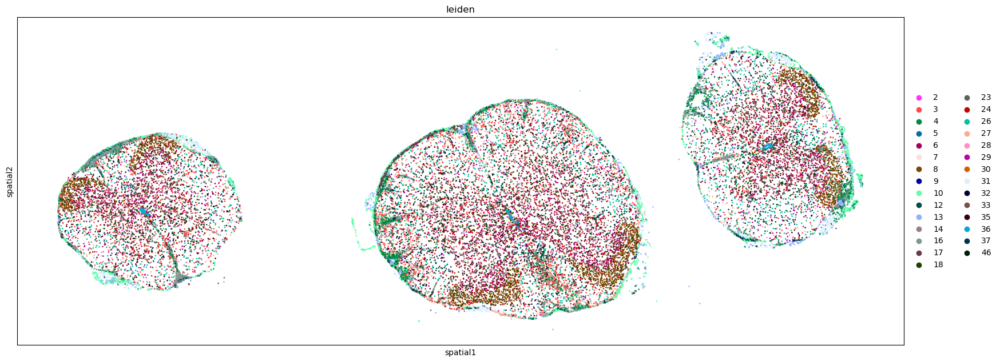

S1-B2


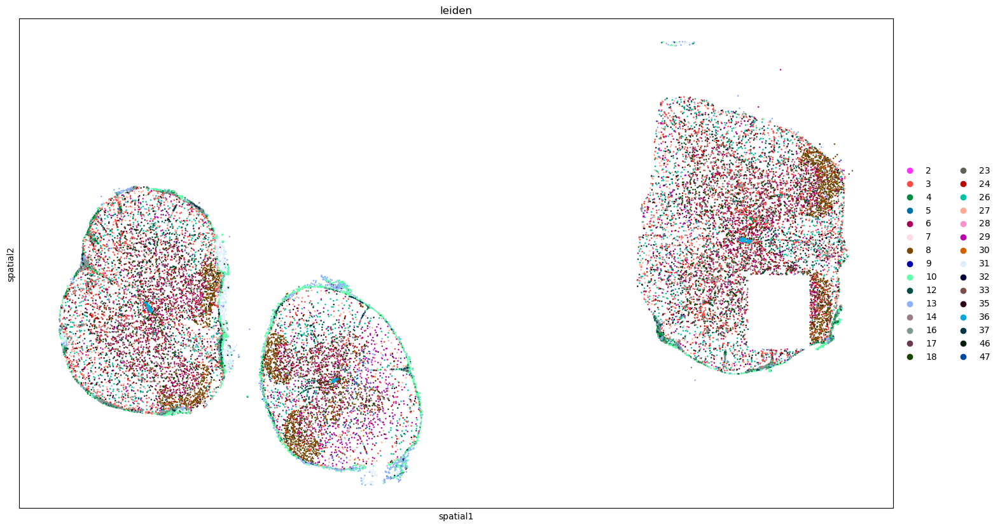

S1-B3


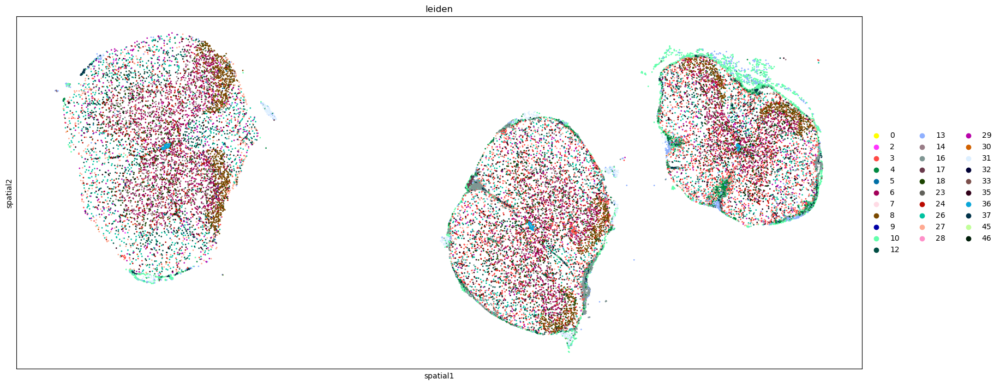

S1-T1


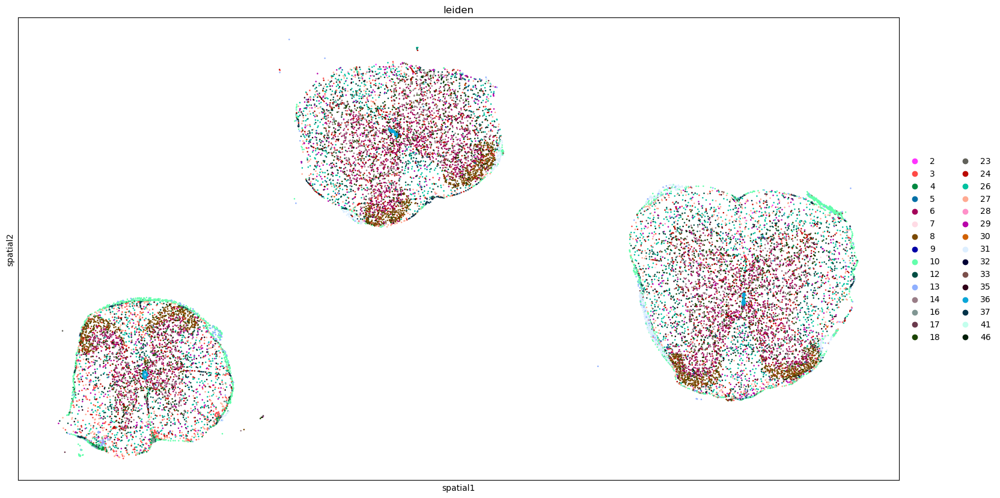

S1-T2


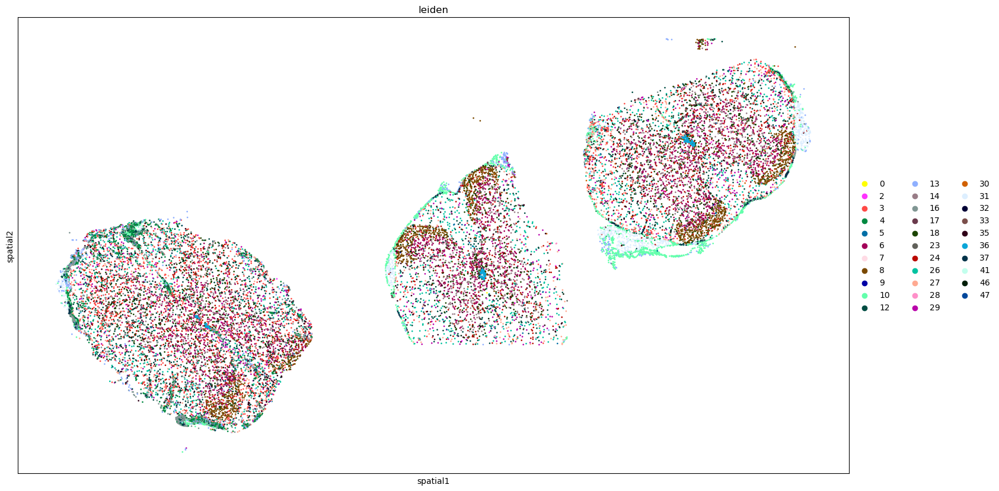

S1-T3


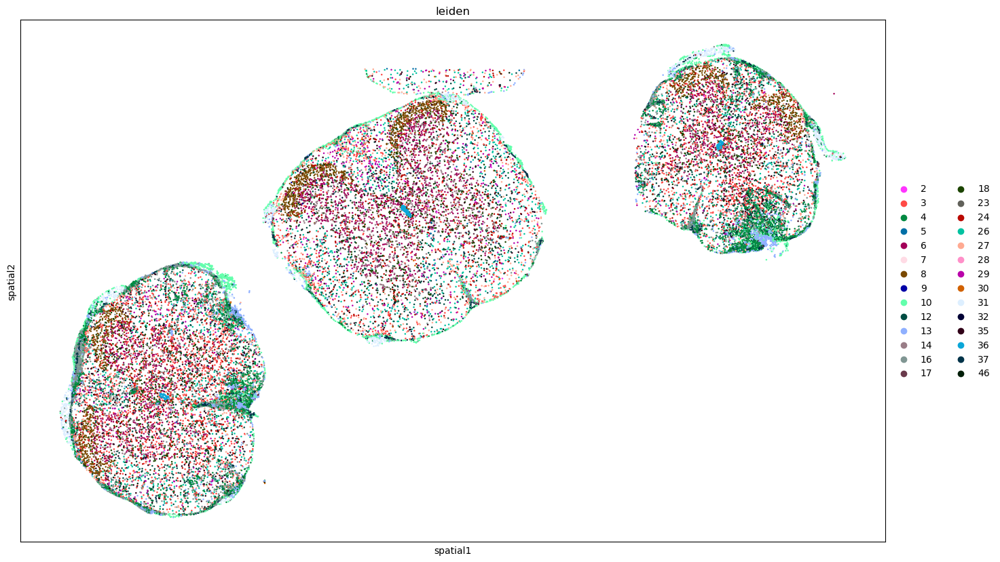

S2-B1


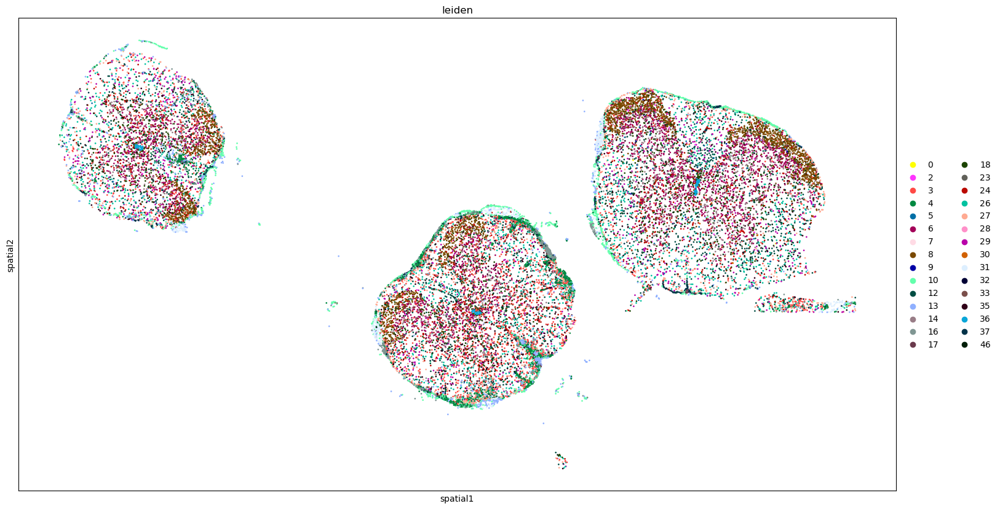

S2-B2


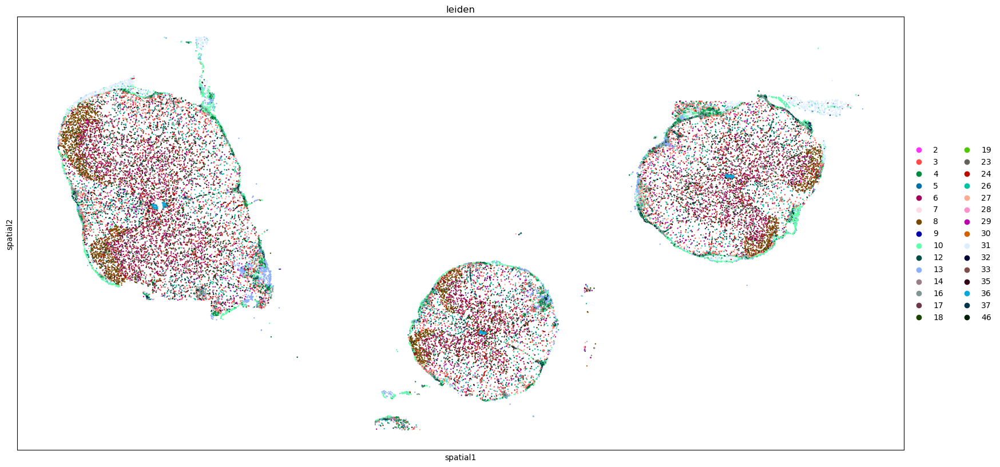

S4-B1


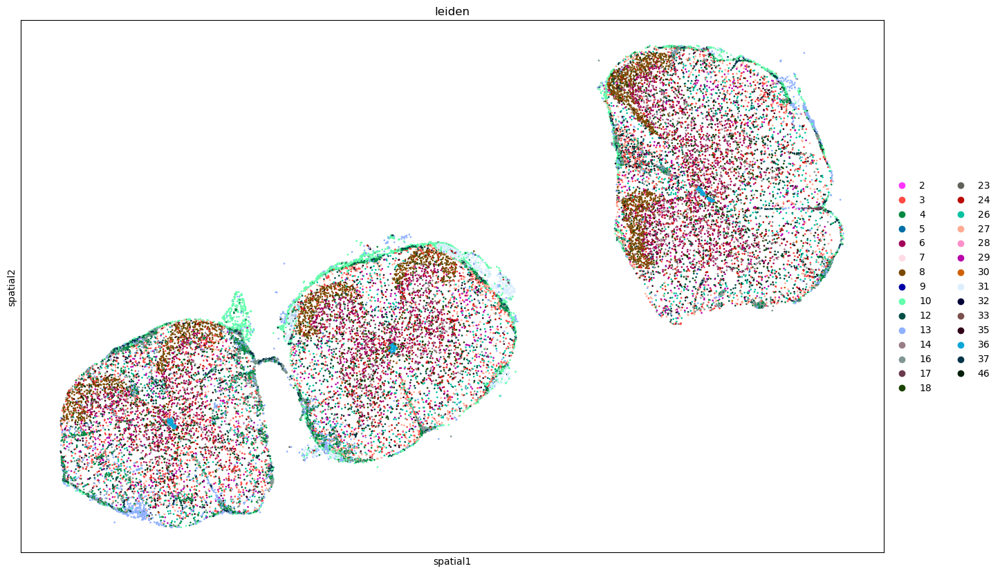

S4-B2


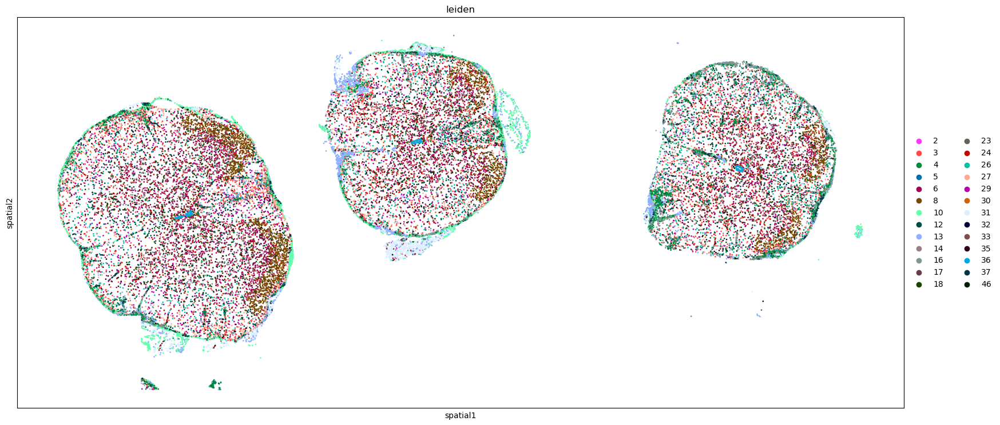

S4-B3


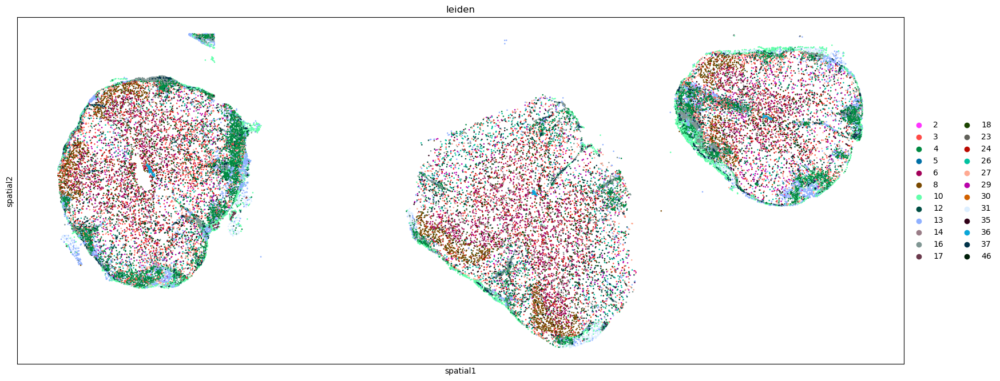

S4-T1


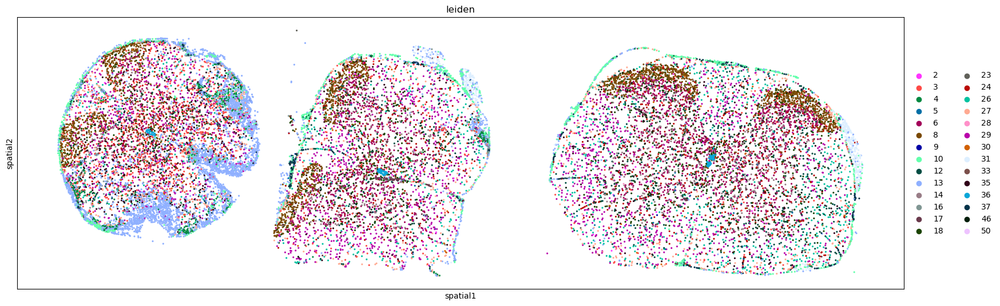

S4-T2


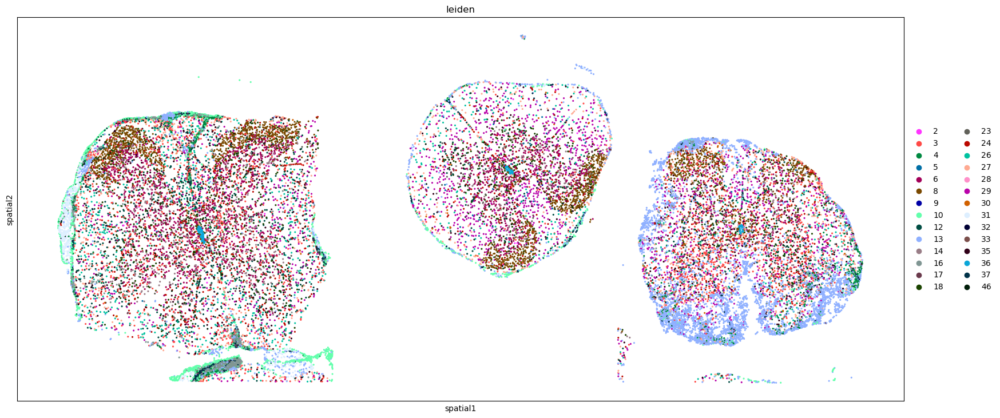

S4-T3


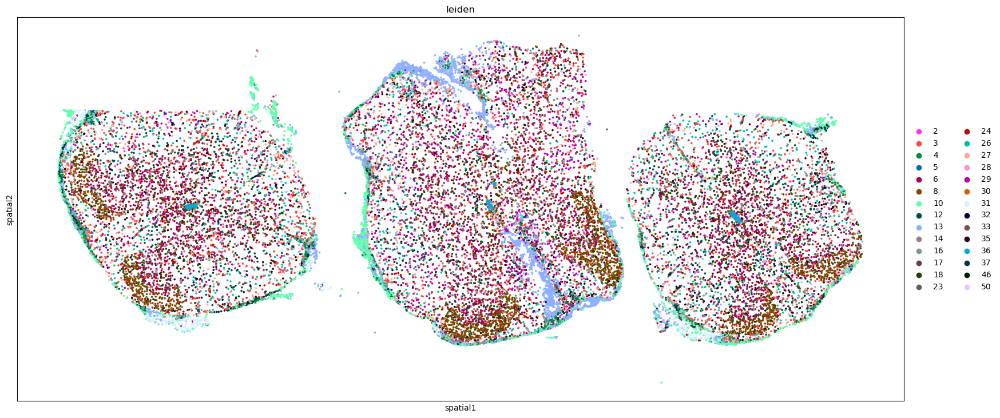

S3-B1


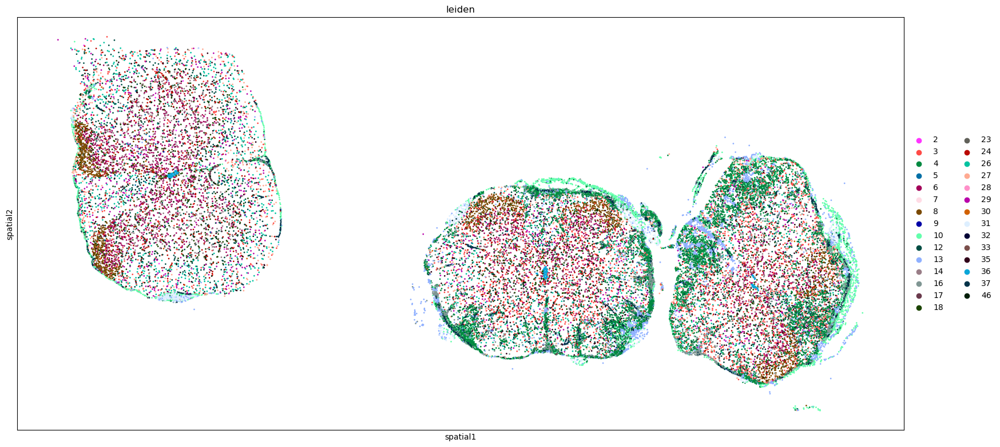

S3-B2


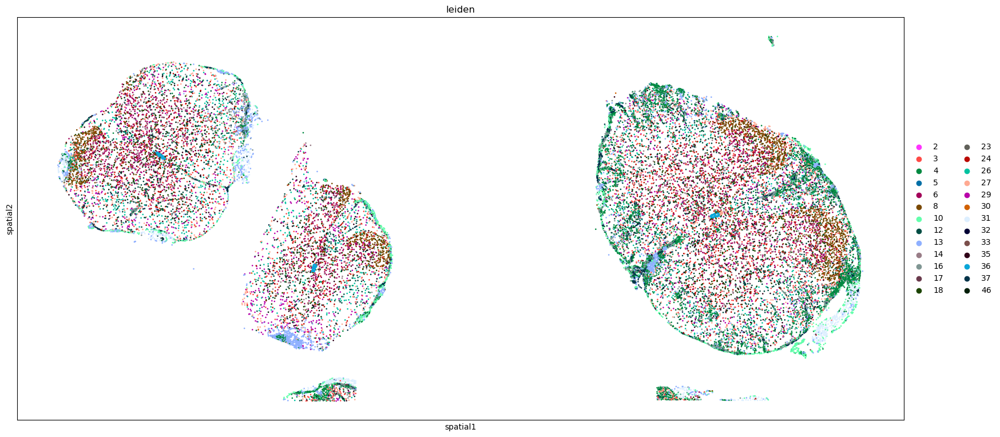

S3-B3


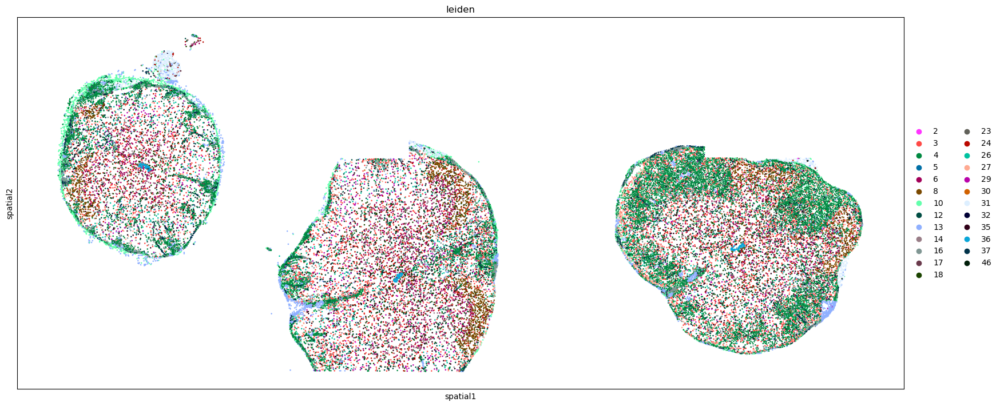

In [19]:
ad_RR = ad[ad.obs.project == 'RREAE']
for run in ad_RR.obs['sample_extracted'].unique():
    print(run)
    ad_int = ad_RR[ad_RR.obs['sample_extracted'] == run]
    with plt.rc_context({'figure.figsize': (20, 10)}):
        sc.pl.spatial(ad_int, spot_size=15, color = 'leiden')
    plt.show()
    

G3_L3


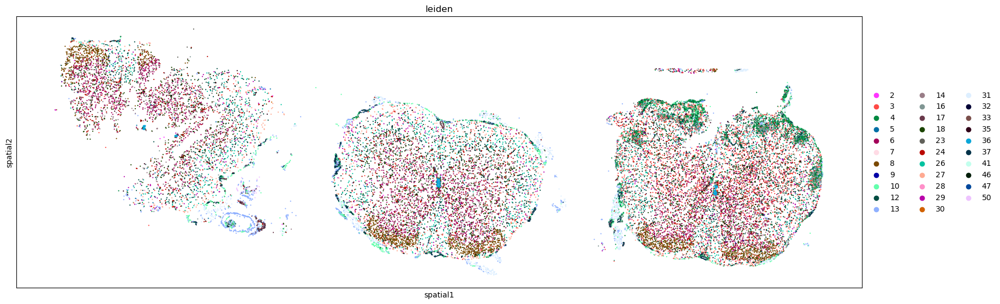

G5_L2


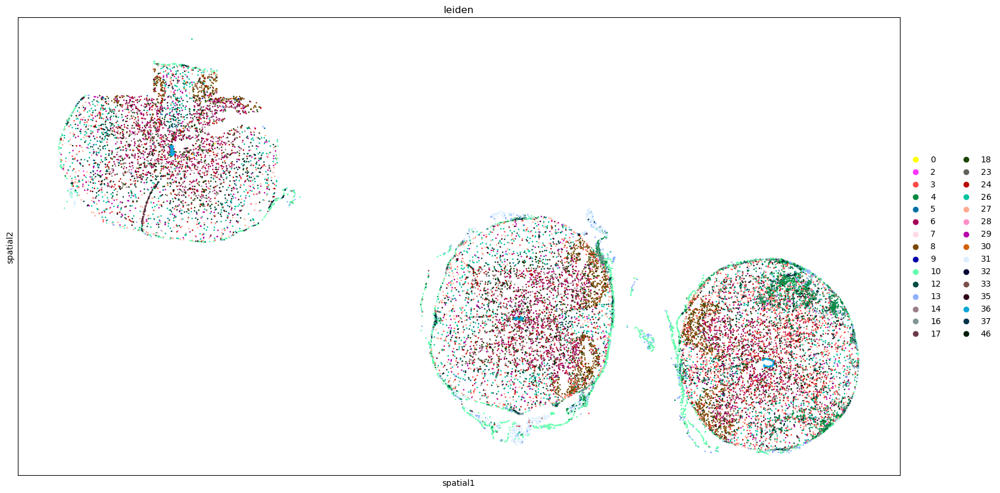

G3_L2


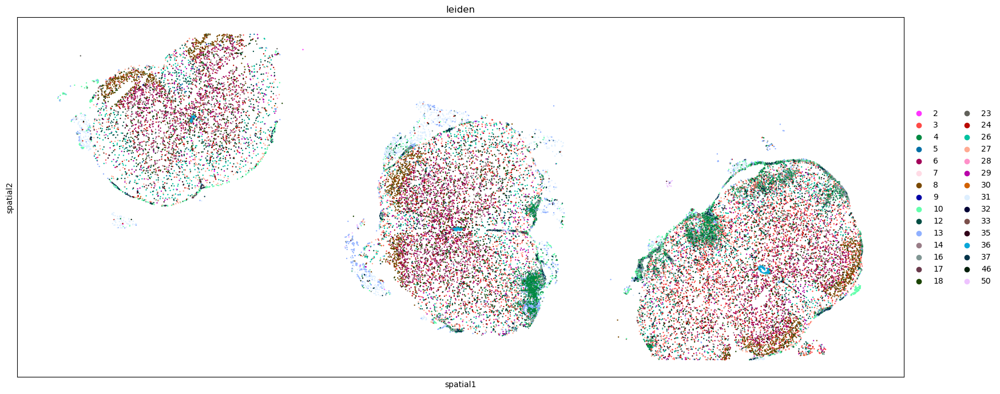

G5_L1


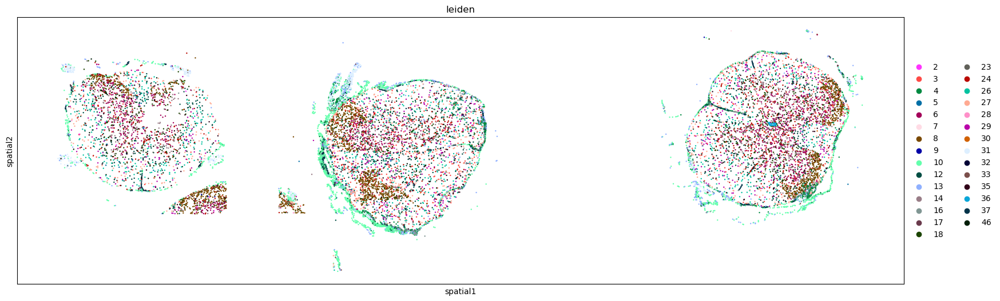

G3_L1


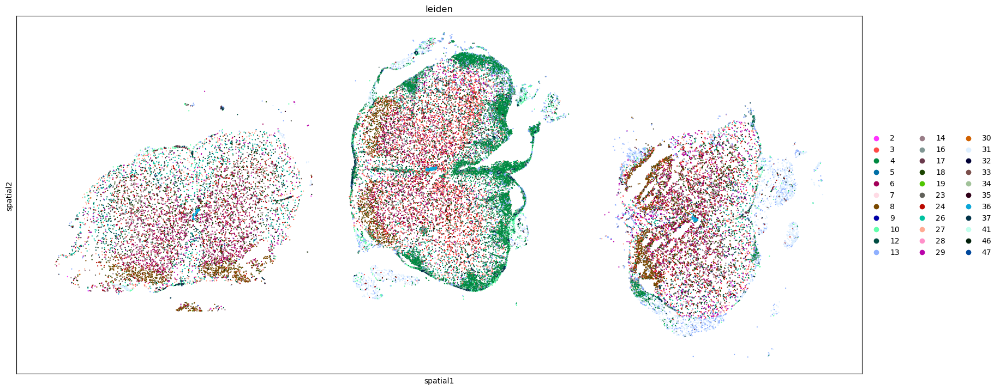

G5_L3


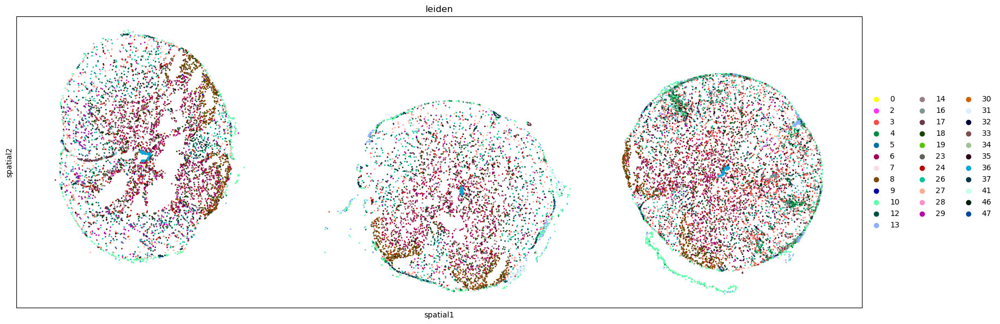

G4_L2


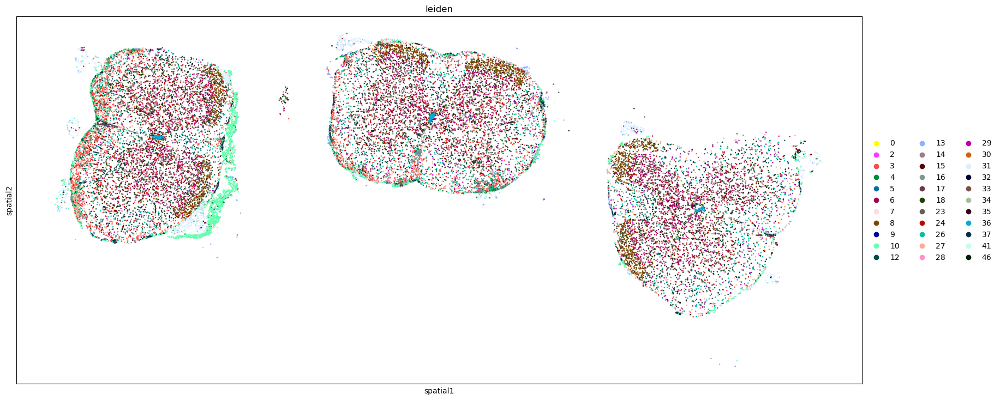

G6_L1


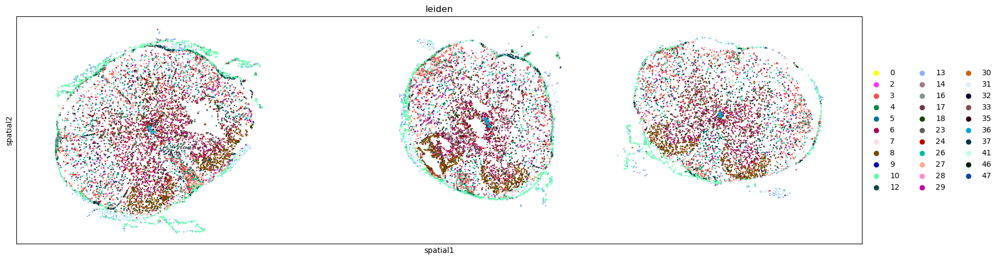

G4_L3


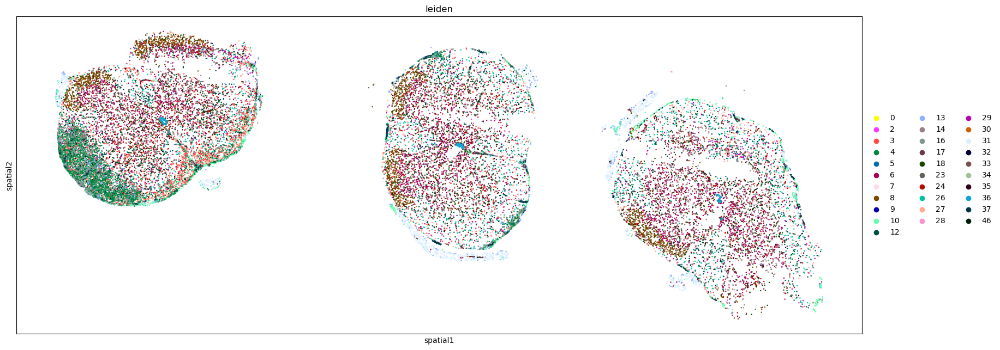

G6_L2


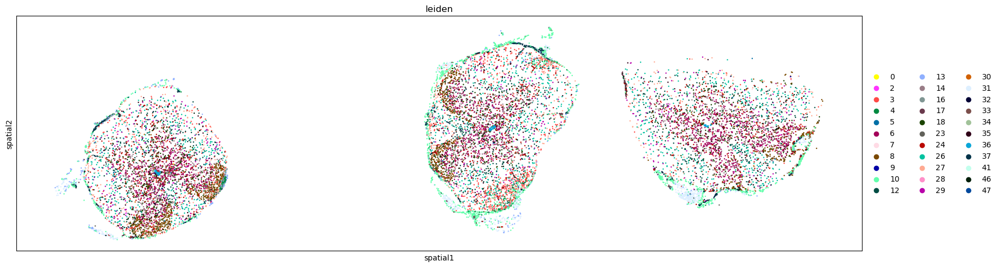

G6_L3


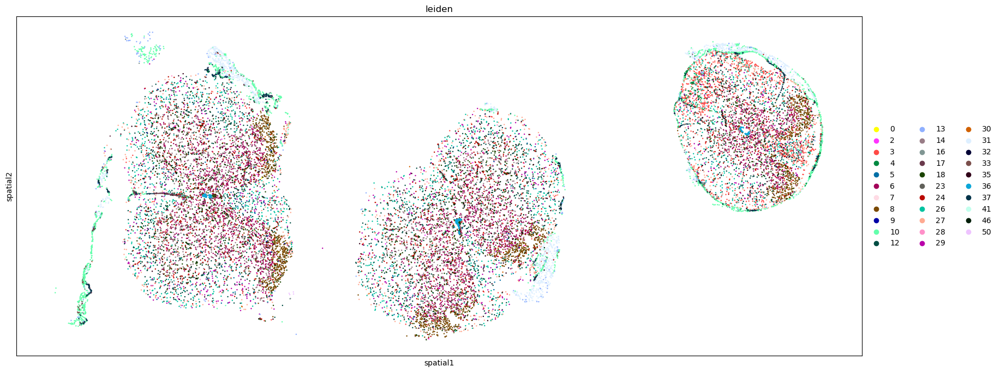

G4_L1


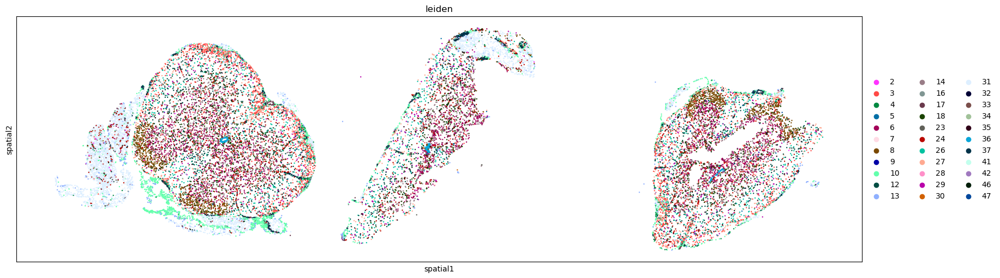

In [20]:
ad_chronic = ad[ad.obs.project == 'Chronic EAE']
for run in ad_chronic.obs['sample_extracted'].unique():
    print(run)
    ad_int = ad_chronic[ad_chronic.obs['sample_extracted'] == run]
    with plt.rc_context({'figure.figsize': (20, 10)}):
        sc.pl.spatial(ad_int, spot_size=15, color = 'leiden')
    plt.show()
    